## Run initial SUMMA model tests ##

In [2]:
from pathlib import Path

# add auto reload for jupyer magic
%load_ext autoreload
%autoreload 2



In [4]:
# Option A: Run a single SUMMA simulation
from snowda.workflows.run_summa_da import run_summa_da

config_path = Path("../runs/examples/ross_summa_da_test.yaml").resolve()
run_dir = run_summa_da(config_path)
print("SUMMA run dir:", run_dir)

2026-10-06 14:05:41 | INFO     | snowda.snowda.workflows.run_summa_da | snowda SUMMA DA run starting
2026-10-06 14:05:41 | INFO     | snowda.snowda.workflows.run_summa_da | Config: /Users/dcasson/GitHub/snowda/runs/examples/ross_summa_da_test.yaml
2026-10-06 14:05:41 | INFO     | snowda.snowda.workflows.run_summa_da | Run dir: /Users/dcasson/GitHub/snowda/outputs/ross_summa_da_test/20261006T200541Z
2026-10-06 14:05:41 | INFO     | snowda.snowda.workflows.run_summa_da | Wrote config snapshot: /Users/dcasson/GitHub/snowda/outputs/ross_summa_da_test/20261006T200541Z/config.resolved.json
2026-10-06 14:05:41 | INFO     | snowda.snowda.io.summa_ensemble | Creating output directories
2026-10-06 14:05:41 | INFO     | snowda.snowda.io.summa_ensemble | Deleting ensemble files in /Users/dcasson/Data/snowda/summa/ross_lumped/settings/SUMMA
2026-10-06 14:05:41 | INFO     | snowda.snowda.io.summa_ensemble | Deleting ensemble files in /Users/dcasson/Data/snowda/summa/ross_lumped/settings/SUMMA
2026-1

FileNotFoundError: No SUMMA output for member 001 matching /Users/dcasson/Data/snowda/summa/ross_lumped/output/001*day.nc

In [ ]:
# SUMMA DA (particle filter, then ESP)
from snowda.workflows.run_summa_da import run_summa_da
config_path = Path("../runs/examples/ross_summa_da.yaml").resolve()
run_dir = run_summa_da(config_path)
print("DA run dir:", run_dir)

## Historic traces, assimilation states, and forecasts

Gray lines are every historic ensemble member. Dotted lines mark assimilation times, and black dots are the member states at those times. Red stars on the SWE plot are the assimilated basin SWE. Colored bands are the ESP forecast from that date, using the same p10–p90 and p25–p75 envelopes as the ESP streamflow plot. Historic streamflow is SUMMA runoff converted to m3 s-1 with the basin area so it matches the routed ESP traces. The orange line is the gauge.

Plotting /Users/dcasson/GitHub/snowda/outputs/ross_summa_da_test/20261007T161454Z


2026-10-07 10:28:58 | INFO     | snowda.snowda.io.da_traces | Loaded DA traces from /Users/dcasson/GitHub/snowda/outputs/ross_summa_da_test/20261007T161454Z: 10 historic members, 3 states, 3 forecasts
2026-10-07 10:28:58 | INFO     | snowda.snowda.io.da_traces | Using HRU area 7494614333.667494 m2 from /Users/dcasson/GitHub/snowda/outputs/ross_summa_da_test/20261007T161454Z/esp/001/2014030100/2010/mizuroute/topology.nc
2026-10-07 10:28:59 | INFO     | snowda.snowda.io.da_traces | Loaded DA traces from /Users/dcasson/GitHub/snowda/outputs/ross_summa_da_test/20261007T161454Z: 10 historic members, 3 states, 3 forecasts


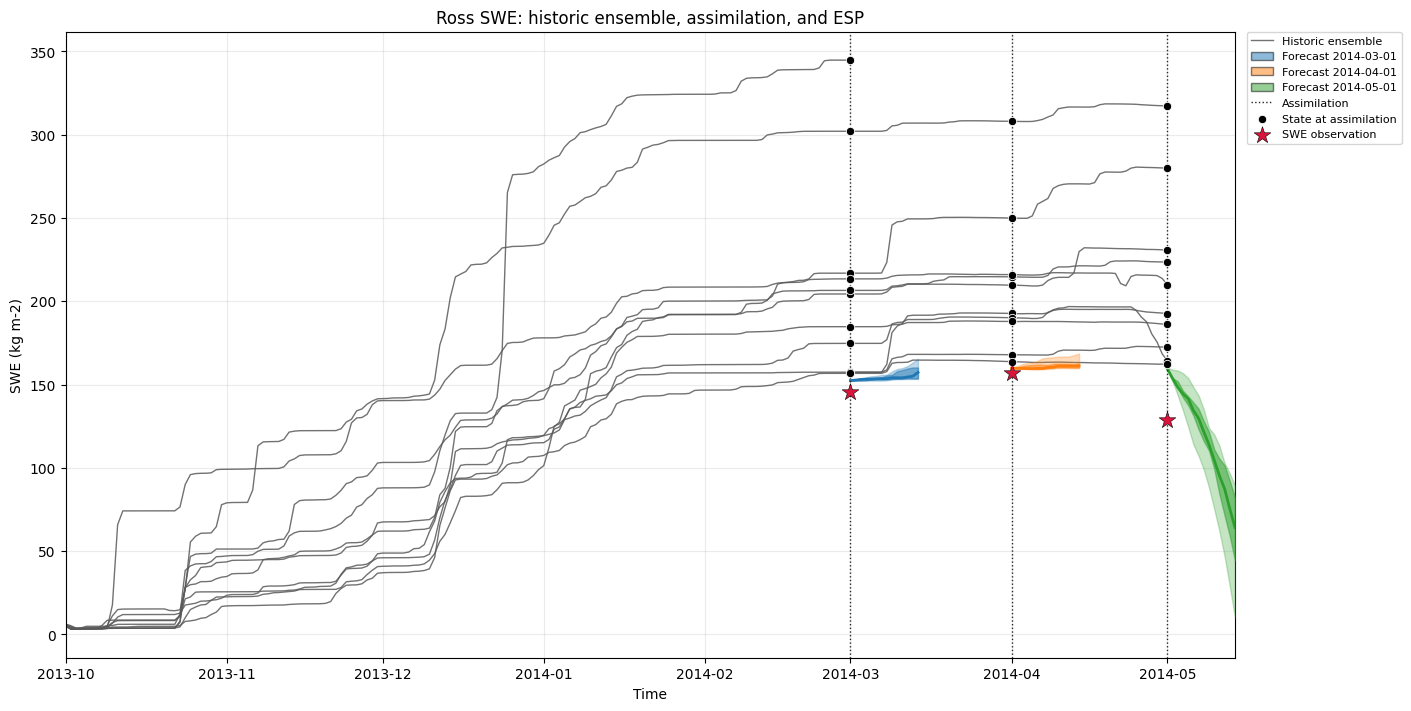

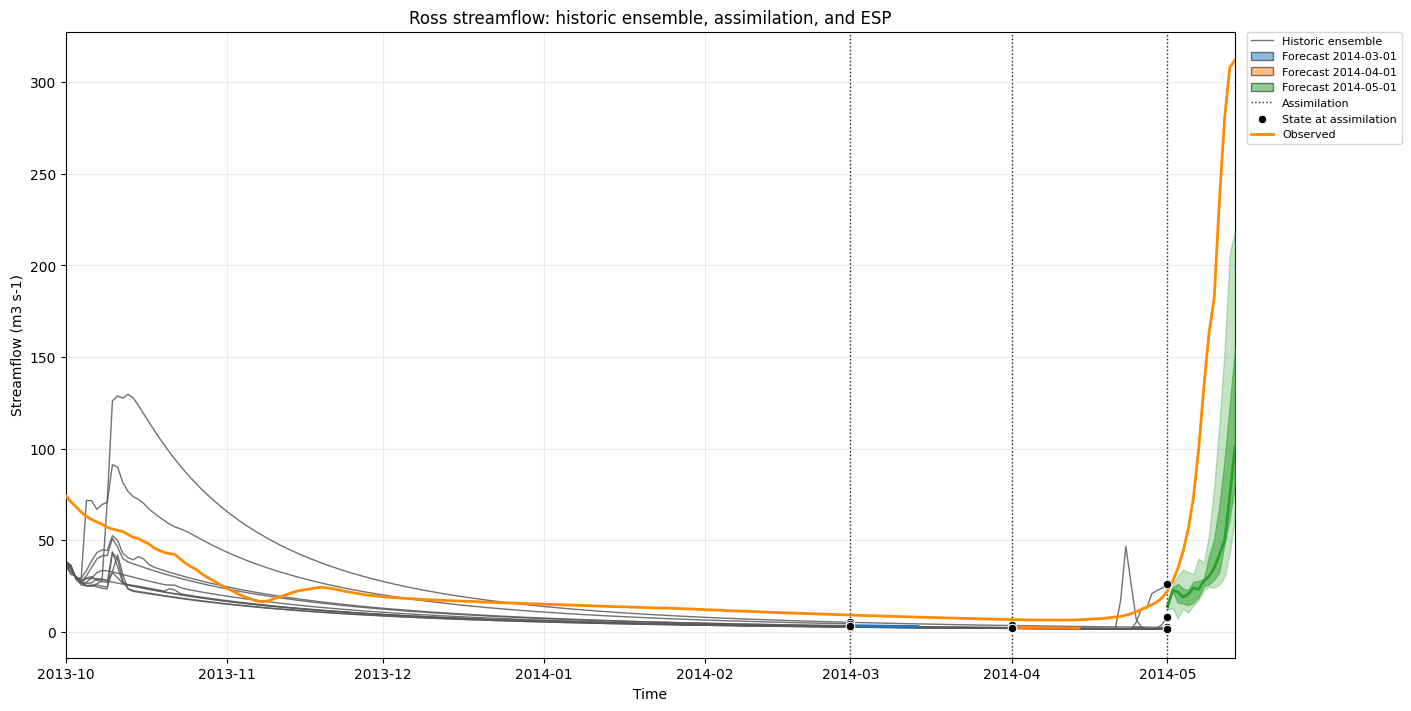

In [5]:
from pathlib import Path

import yaml

from snowda.io.da_traces import load_da_streamflow, load_da_swe
from snowda.io.streamflow import read_streamflow_observations
from snowda.viz.summa_da import plot_da_traces

if (
    "run_dir" in globals()
    and (Path(run_dir) / "summa").is_dir()
    and (Path(run_dir) / "esp").is_dir()
):
    da_run_dir = Path(run_dir)
else:
    run_root = Path("../outputs/ross_summa_da_test")
    da_run_dir = max(
        (
            path
            for path in run_root.iterdir()
            if (path / "summa").is_dir() and (path / "esp").is_dir()
        ),
        key=lambda path: path.stat().st_mtime,
    )
print("Plotting", da_run_dir)

figure_dir = da_run_dir / "figures"
figure_dir.mkdir(exist_ok=True)

swe = load_da_swe(da_run_dir)
fig, _ax = plot_da_traces(
    swe,
    title="Ross SWE: historic ensemble, assimilation, and ESP",
)
fig.savefig(figure_dir / "da_swe.png", dpi=150, bbox_inches="tight")

eval_cfg = yaml.safe_load(
    Path("../runs/examples/ross_evaluate_esp.yaml").read_text()
)
obs = read_streamflow_observations(eval_cfg["obs_csv"])
flow = load_da_streamflow(da_run_dir)
fig, _ax = plot_da_traces(
    flow,
    obs,
    title="Ross streamflow: historic ensemble, assimilation, and ESP",
)
fig.savefig(figure_dir / "da_streamflow.png", dpi=150, bbox_inches="tight")